# Does Motilal Oswal Midcap Fund show skill? A reproducible walkthrough

**Question.** Where does the fund's return come from (sectors vs stock picks), how different is it from its benchmark,
what style does it behave like, and is its alpha distinguishable from luck?

**Fund.** Motilal Oswal Midcap Fund – Direct Plan Growth (AMFI 127042). **Benchmark:** Nifty Midcap 150 TRI.

**How this notebook works.** Every section re-runs the project's own analysis script (`analysis/t*.py`) on the
committed data snapshot in `data/processed/`, then shows the key tables and charts. Nothing is hard-coded: if you
rebuild the data (`python run_all.py --rebuild`), every number below updates.

> Data notes: benchmark and style indices are **index-fund NAV proxies** (official TRI downloads are not permitted
> from niftyindices.com); stock returns exclude dividends; factors are from the IIMA data library.

In [1]:
import sys, io, contextlib
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "analysis"))
import a_common as A

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

def quiet(module):
    """Run an analysis script's main() without its console printout."""
    with contextlib.redirect_stdout(io.StringIO()):
        module.main()

def show(path, width=850):
    display(Image(filename=str(A.RES / path), width=width))

display(Markdown("**Sample windows (derived from the data):**"))
pd.Series(A.windows())

**Sample windows (derived from the data):**

FUND_START         2014-03-31
BENCH_START        2019-10-31
HOLD_START         2019-09-30
STYLE_START        2020-01-31
FACTOR_END         2025-12-31
LAST_FULL_MONTH    2026-09-30
dtype: object

## 0. Data snapshot
Row counts, date ranges and SHA-256 checksums of every analysis input (`data/processed/MANIFEST.csv`).

In [2]:
pd.read_csv(ROOT / "data/processed/MANIFEST.csv")[["file", "rows", "columns", "date_range", "built"]]

,file,rows,columns,date_range,built
0,factors_iima.csv,168,6,2012-01-31..2025-12-31,2026-10-15
1,fund_monthly_meta.csv,237,9,2014-02-28..2026-09-30,2026-10-15
2,holdings_monthly.csv,16439,11,2014-02-28..2026-09-30,2026-10-15
3,isin_master.csv,16071,5,NaN,2026-10-15
4,isin_remap.csv,69,4,NaN,2026-10-15
5,midcap_category_schemes.csv,81,6,NaN,2026-10-15
6,nav_daily.csv,63123,7,2013-01-01..2026-10-14,2026-10-15
7,portfolio_files.csv,181,6,2012-10-31..2026-10-08,2026-10-15
8,portfolio_parse_misses.csv,24,2,NaN,2026-10-15
9,price_coverage.csv,237,3,2014-02-28..2026-09-30,2026-10-15


## 1. The big picture
Growth of ₹100 since the benchmark proxy starts, and drawdowns. The charts are produced by `analysis/t6_charts.py`.

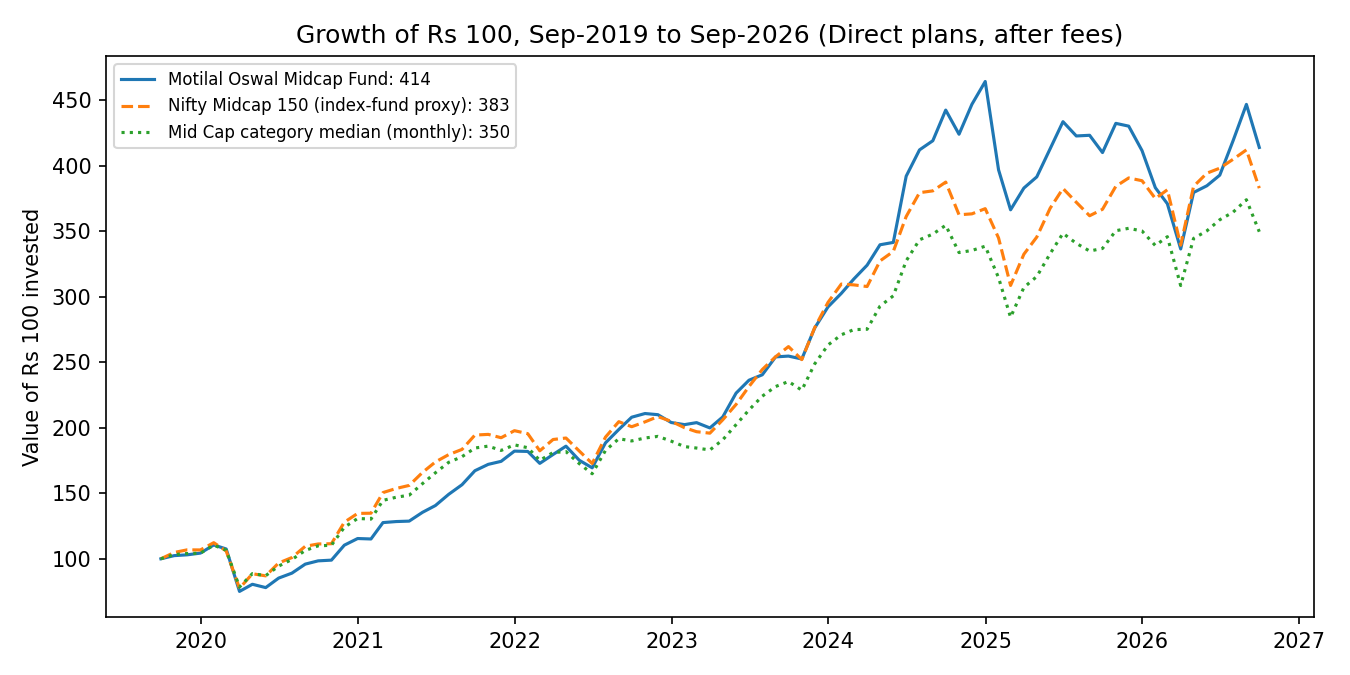

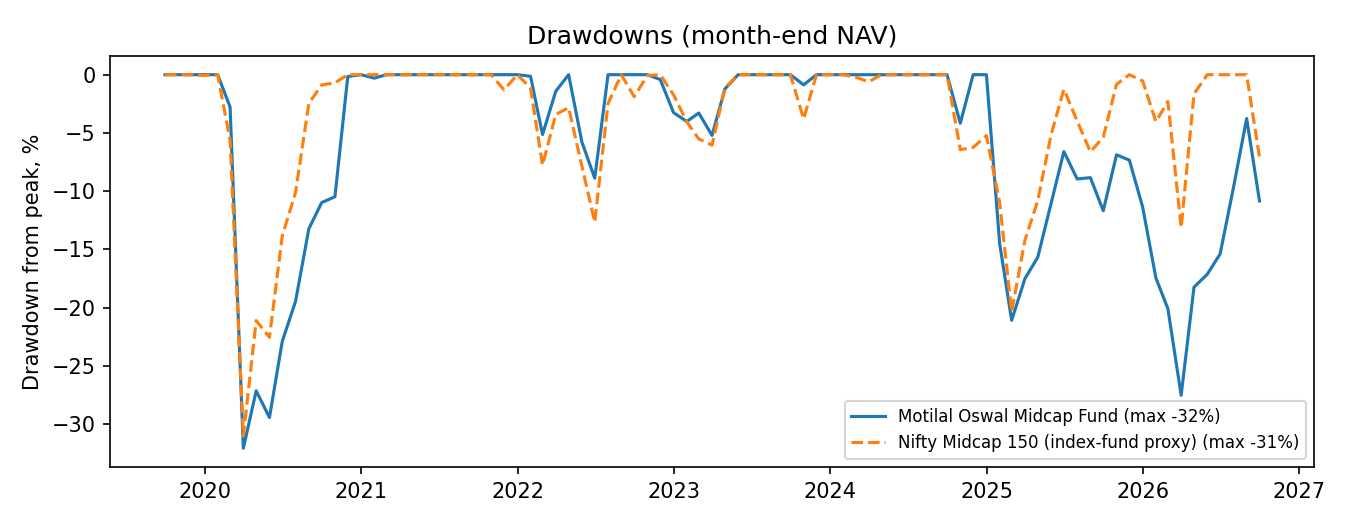

In [3]:
import t1_brinson, t2_active_share, t3_style, t4_alpha_capture, t5_skill_luck, t6_charts
quiet(t1_brinson); quiet(t2_active_share)   # t6 draws charts from t1/t2 outputs
quiet(t6_charts)
show("t0/growth_of_100.png"); show("t0/drawdowns.png")

## 2. Brinson-Fachler sector attribution (holdings-based)

For each month, sector weights at the previous month-end ($w$) and next-month stock returns ($R$):

* **Allocation** $=(w_{p,i}-w_{b,i})(R_{b,i}-R_b)$: did the fund overweight sectors that beat the benchmark?
* **Selection** $=w_{b,i}(R_{p,i}-R_{b,i})$: did its stocks beat the benchmark's stocks within each sector?
* **Interaction** $=(w_{p,i}-w_{b,i})(R_{p,i}-R_{b,i})$

They sum exactly to $R_p-R_b$ each month (checked in code); months are linked with Carino's method. Cash is a
sector earning the T-bill rate. The **return gap** compares actual NAV returns with this holdings-based return
(it captures intra-month trading, fees and dividends).

,value
months,84
window,2019-10-31..2026-09-30
holdings_fund_cum,2.65953096282649
holdings_bench_cum,2.6946454535333078
holdings_active_cum,-0.035114490706817936
linked_allocation,-1.0678673332213935
linked_selection,0.7152195364660455
linked_interaction,0.3175333060485325
nav_fund_cum,3.139123038781011
nav_bench_proxy_cum,2.828376345330396


,avg_w_fund,avg_w_bench,allocation,selection,interaction,total
sector,,,,,,
Consumer Discretionary,0.295,0.196,-0.126,0.498,0.128,0.500
Industrials,0.122,0.162,-0.046,0.572,-0.131,0.395
Real Estate,0.051,0.033,0.011,0.089,0.102,0.203
Consumer Staples,0.021,0.041,0.108,-0.122,0.066,0.052
Telecom,0.019,0.019,0.087,-0.011,-0.029,0.046
Information Technology,0.103,0.059,-0.226,0.126,0.106,0.006
Cash & equivalents,0.082,0.000,-0.079,0.000,0.000,-0.079
Health Care,0.049,0.106,-0.190,0.017,-0.043,-0.216
Materials,0.065,0.109,-0.050,-0.224,0.039,-0.235


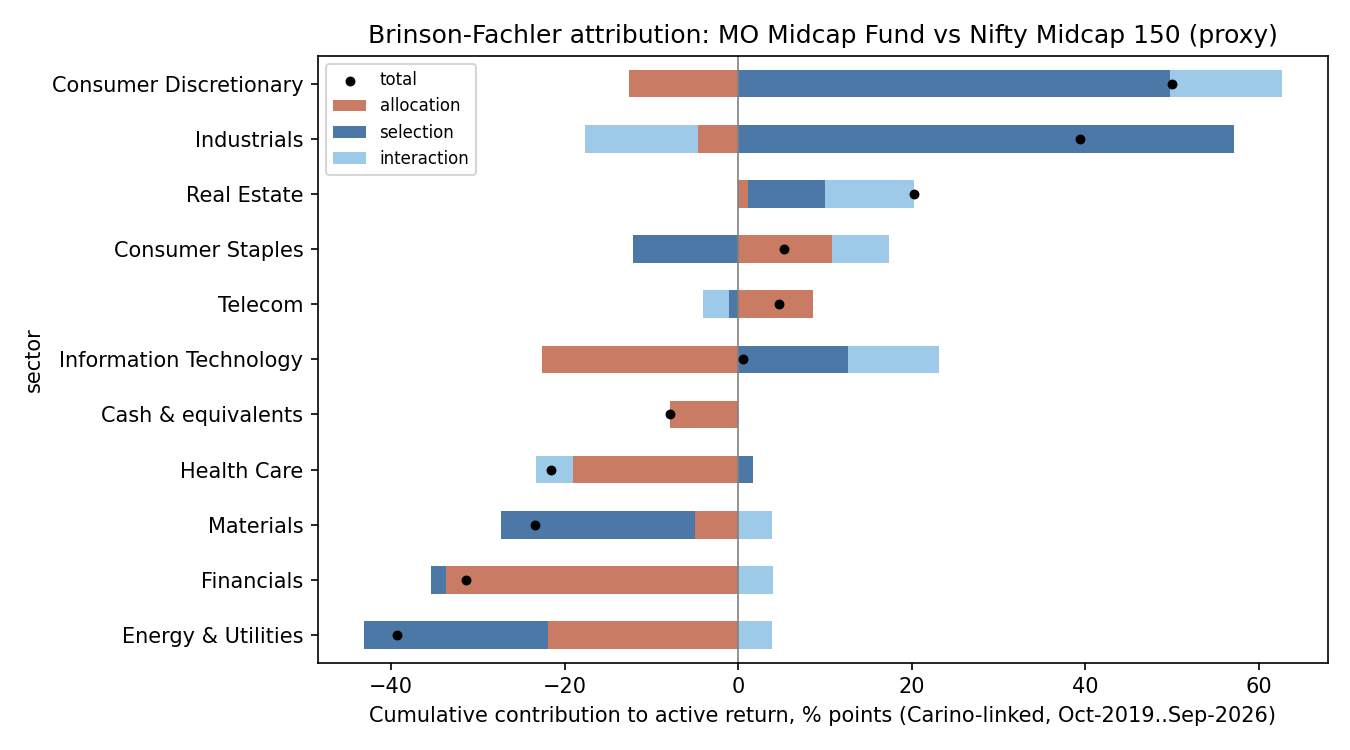

,year,allocation,selection,interaction,active_holdings_based
0,2019,-0.003,-0.019,0.010,-0.012
1,2020,-0.111,0.005,-0.008,-0.113
2,2021,-0.077,0.123,0.010,0.056
3,2022,0.008,0.011,0.044,0.063
4,2023,-0.035,-0.008,-0.001,-0.045
5,2024,0.022,0.176,0.005,0.203
6,2025,-0.082,-0.090,-0.010,-0.183
7,2026,-0.019,0.001,0.034,0.016


In [4]:
s = pd.read_csv(A.RES / "t1/brinson_summary.csv", index_col=0)["value"]
display(s.to_frame())
display(pd.read_csv(A.RES / "t1/brinson_cumulative_by_sector_carino.csv", index_col=0).round(3))
show("t1/brinson_by_sector.png")
pd.read_csv(A.RES / "t1/brinson_by_calendar_year_arithmetic.csv").round(3)

## 3. Active share (Cremers & Petajisto 2009)

$AS=\tfrac12\sum_i|w_{p,i}-w_{b,i}|$ over all stocks held by the fund or the benchmark proxy. 0 = index clone,
1 = no overlap; above ~0.8 is usually called concentrated stock-picking.

,mean,min,50%,max
month_end,2023-03-31 18:38:07.058823424,2019-09-30 00:00:00,2023-03-31 00:00:00,2026-09-30 00:00:00
active_share_equity,0.8249860048506571,0.7744977004182223,0.8259976751192936,0.8893037905447744
active_share_nav_incl_cash,0.8258910450691843,0.7760818471422022,0.8267163641917817,0.8893037905447743
n_stocks_fund,25.68235294117647,15.0,26.0,34.0
n_stocks_bench,150.12941176470588,150.0,150.0,152.0
fund_cash_weight,0.08177794610300815,0.006090563613742606,0.06080184406523104,0.2544304798385624
top10_weight_fund_equity,0.6768179569161229,0.5255319320555113,0.6953534224183167,0.8403392356222017
n_fund_in_bench,18.223529411764705,11.0,18.0,25.0
fund_equity_weight_in_bench,0.7520018455947592,0.6182107122195393,0.7516114110683928,0.9208225454231033


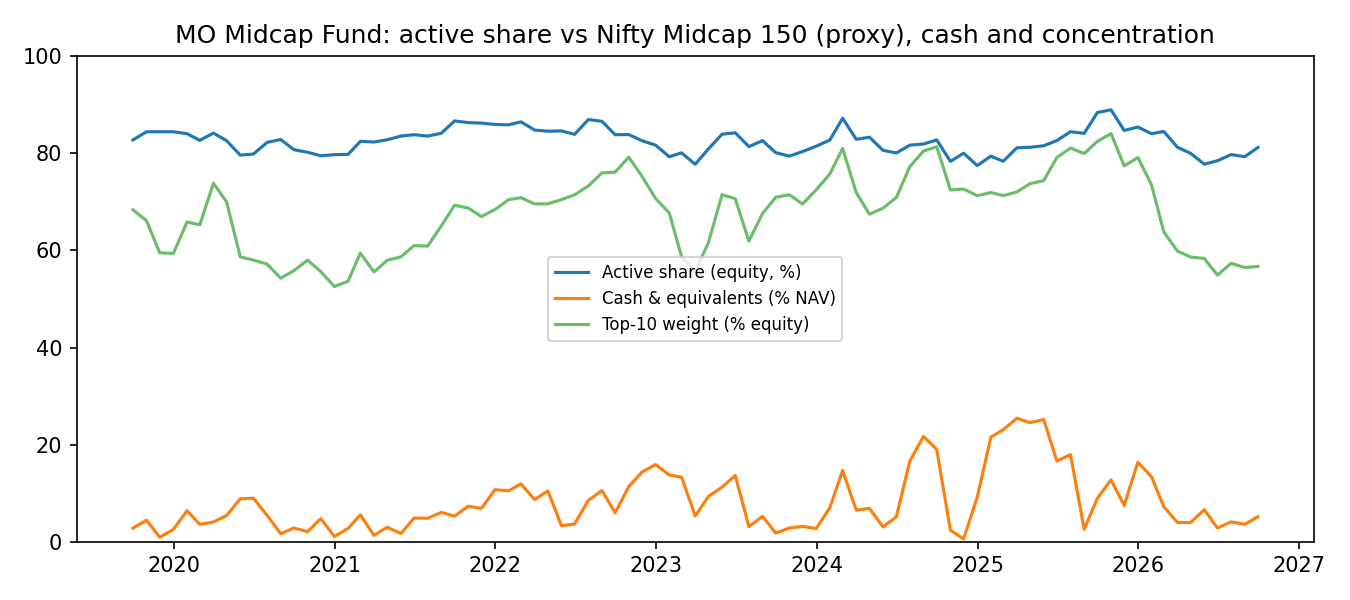

,year,active_share_equity,n_stocks_fund,top10_weight_fund_equity,fund_equity_weight_in_bench,fund_cash_weight
0,2019,0.840,22.750,0.633,0.660,0.027
1,2020,0.815,26.750,0.604,0.739,0.046
2,2021,0.839,26.417,0.621,0.729,0.050
3,2022,0.846,25.500,0.727,0.726,0.096
4,2023,0.809,30.500,0.666,0.720,0.071
5,2024,0.816,23.250,0.742,0.777,0.094
6,2025,0.833,21.083,0.772,0.842,0.169
7,2026,0.807,27.778,0.599,0.765,0.057


In [5]:
display(pd.read_csv(A.RES / "t2/active_share_summary.csv", index_col=0).round(3))
show("t2/active_share.png")
pd.read_csv(A.RES / "t2/active_share_by_year.csv").round(3)

## 4. Returns-based style analysis (Sharpe 1992)

Find non-negative weights summing to 1 on style indices (Nifty 50, Next 50, Midcap 150, Smallcap 250, cash) that
best replicate the fund's monthly returns. $R^2$ = share explained by style; $1-R^2$ = selection.

,value
N50,0.0000
NN50,0.0000
MID150,0.6244
SC250,0.2679
CASH,0.1077
R2,0.8166
selection_1_minus_R2,0.1834
months,81.0000
mean_monthly_residual (style alpha),0.0026
annualised_tracking_error_vs_style,0.0934


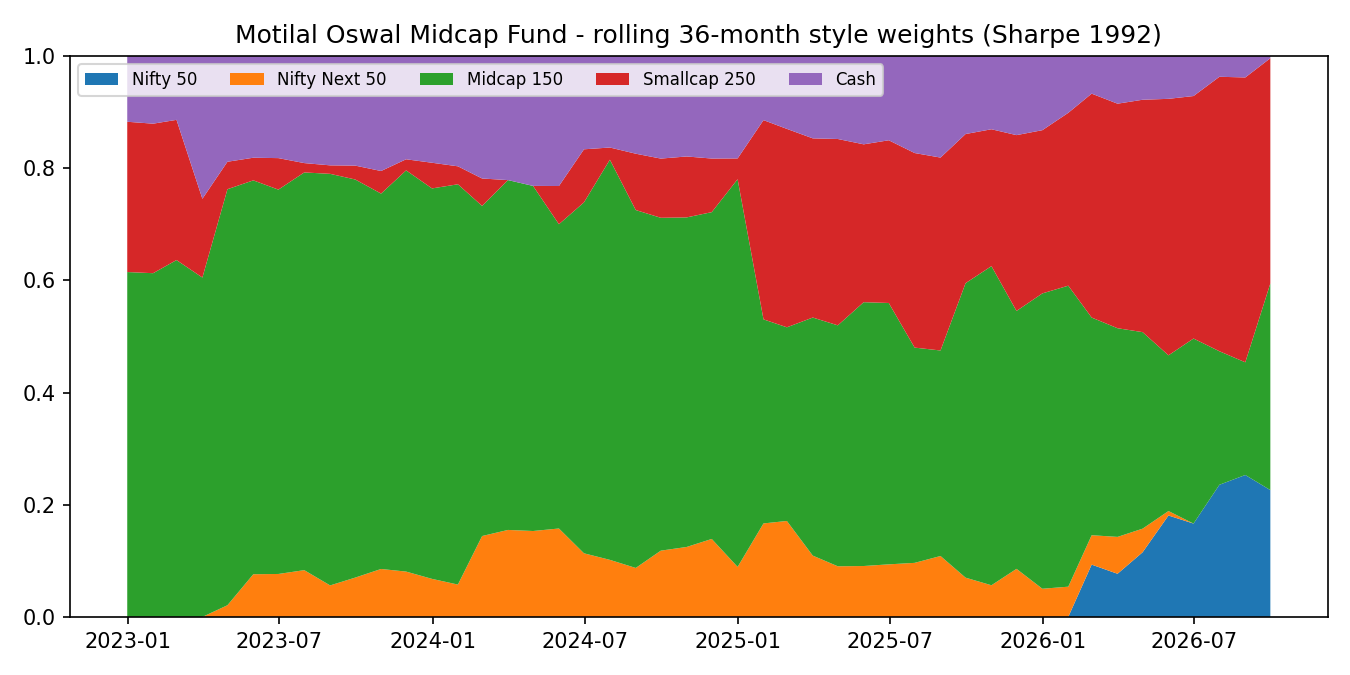

In [6]:
quiet(t3_style)
display(pd.read_csv(A.RES / "t3/style_full_period.csv", index_col=0).round(4))
show("t3/style_rolling_36m.png")

## 5. Four-factor alpha and capture ratios

$r_{fund}-r_f=\alpha+\beta_1 MKT+\beta_2 SMB+\beta_3 HML+\beta_4 WML+\varepsilon$ with IIMA Indian factors and
Newey-West standard errors. **Control:** the same regression on the passive Midcap 150 index fund. If the passive
fund also shows "alpha", the model is mispricing mid caps, not detecting skill.

series,Fund (full),Fund (benchmark window),Midcap 150 index-fund proxy [control]
start,2014-03-31,2019-10-31,2019-10-31
end,2025-12-31,2025-12-31,2025-12-31
months,142,75,75
nw_lags,4,3,3
alpha_monthly,0.006238,0.006006,0.003
alpha_annualised,0.077477,0.074507,0.036603
alpha_t_nw,2.625219,1.537169,1.432732
alpha_p_nw,0.008659,0.124252,0.151934
adj_R2,0.74056,0.720261,0.901845
beta_MKT_RF,0.90911,0.894101,0.987027


vs,Nifty Midcap 150 proxy (Oct-2019..Sep-2026),IIMA market MKT_RF+RF (Mar-2014..Dec-2025)
months,84.000000,142.000000
up_months,58.000000,92.000000
down_months,26.000000,50.000000
up_capture,0.963603,1.073975
down_capture,0.866166,0.775288
fund_cagr,0.224982,0.227298
bench_cagr,0.211401,0.162741
batting_avg,0.476190,0.619718


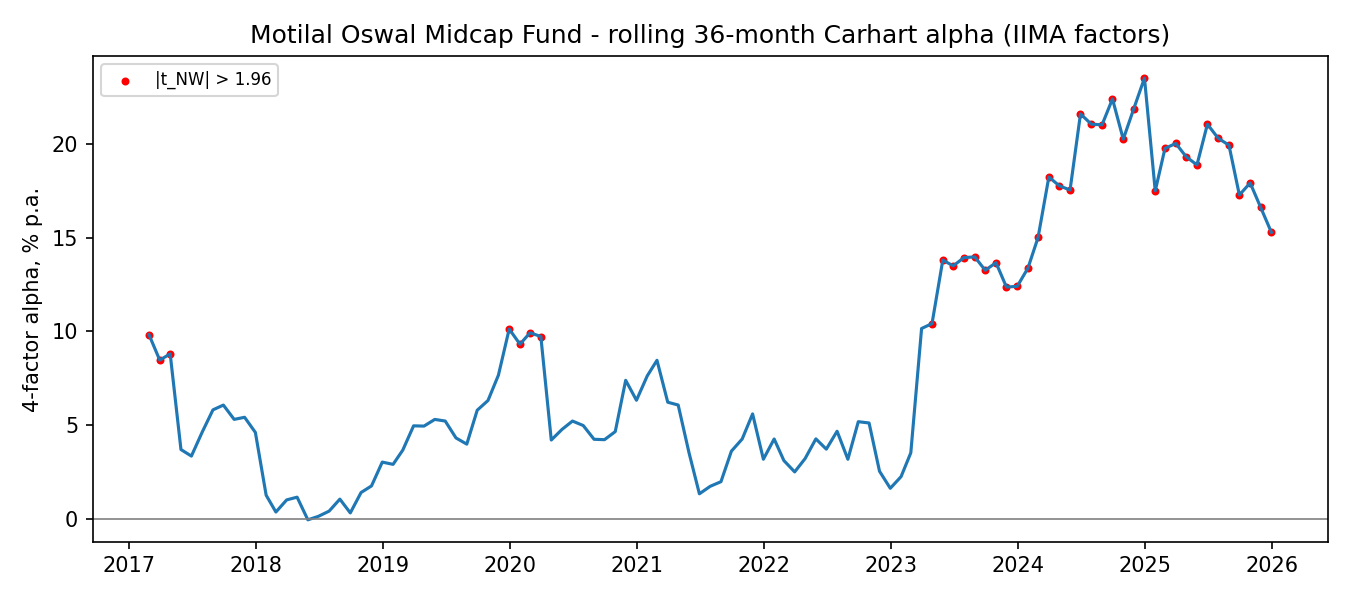

In [7]:
quiet(t4_alpha_capture)
display(pd.read_csv(A.RES / "t4/carhart_alpha.csv").set_index("series").T)
display(pd.read_csv(A.RES / "t4/up_down_capture.csv").set_index("vs").T)
show("t4/rolling_36m_alpha.png")

## 6. Skill vs luck (bootstrap, Kosowski et al. 2006; Fama & French 2010)

Set every mid-cap fund's alpha to zero, resample months jointly (same months for all funds and factors), and
re-estimate the t-statistics 2,000 times. If the fund's actual t is rarely reached by these luck-only runs, it is
evidence of skill. Run twice: against the IIMA factors, and against the passive mid-cap benchmark itself.

**Model: carhart_iima**

,value
funds_in_test,18
bootstrap_runs,2000
seed,20261015
model,carhart_iima
window,2014-03..2025-12
target_alpha_annualised,0.0774773914299447
target_t_ols,2.414721267583974
target_rank,5
target_p_boot (share of luck-only runs with t >= actual),0.02
target_sim_t_95th_pct,1.8802669908714176


,pct,actual_t,sim_mean_t,share_sim_ge_actual
0,5,0.763,-0.973,0.006
1,10,0.903,-0.768,0.010
2,25,1.357,-0.385,0.012
3,50,2.109,0.040,0.003
4,75,2.397,0.453,0.006
5,90,2.695,0.840,0.006
6,95,2.810,1.043,0.011


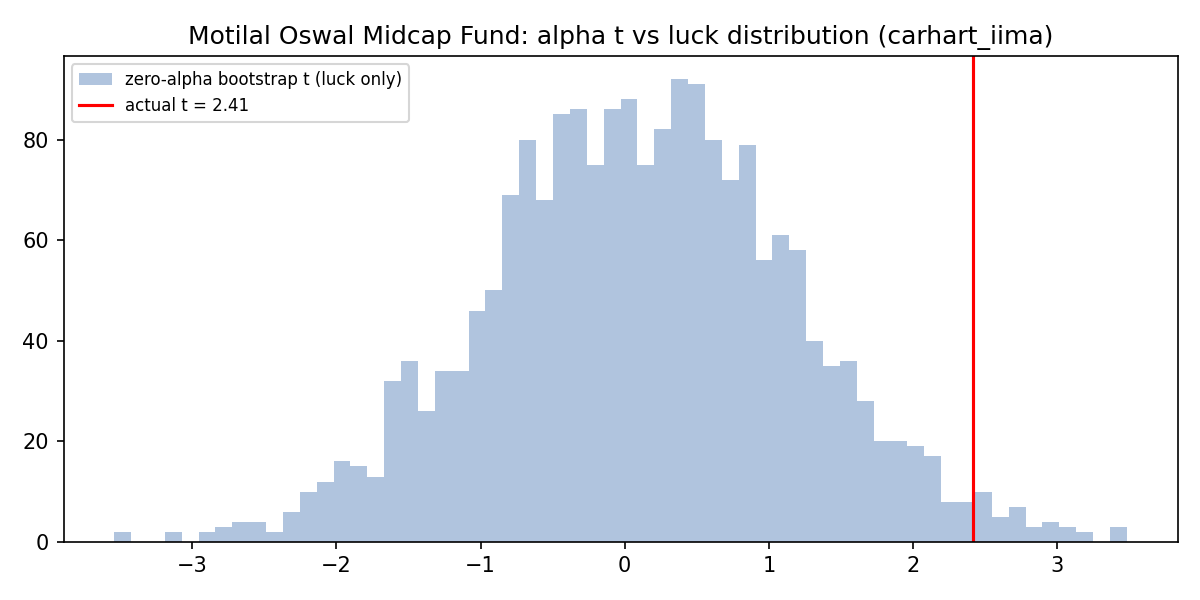

**Model: benchmark_mid150**

,value
funds_in_test,19
bootstrap_runs,2000
seed,20261015
model,benchmark_mid150
window,2019-10..2026-09
target_alpha_annualised,0.026407223803158297
target_t_ols,0.7086856753922631
target_rank,7
target_p_boot (share of luck-only runs with t >= actual),0.3065
target_sim_t_95th_pct,2.048923153632699


,pct,actual_t,sim_mean_t,share_sim_ge_actual
0,5,-1.314,-1.175,0.606
1,10,-0.977,-0.928,0.542
2,25,-0.519,-0.460,0.537
3,50,0.199,0.087,0.416
4,75,1.089,0.641,0.236
5,90,1.264,1.114,0.392
6,95,1.356,1.361,0.479


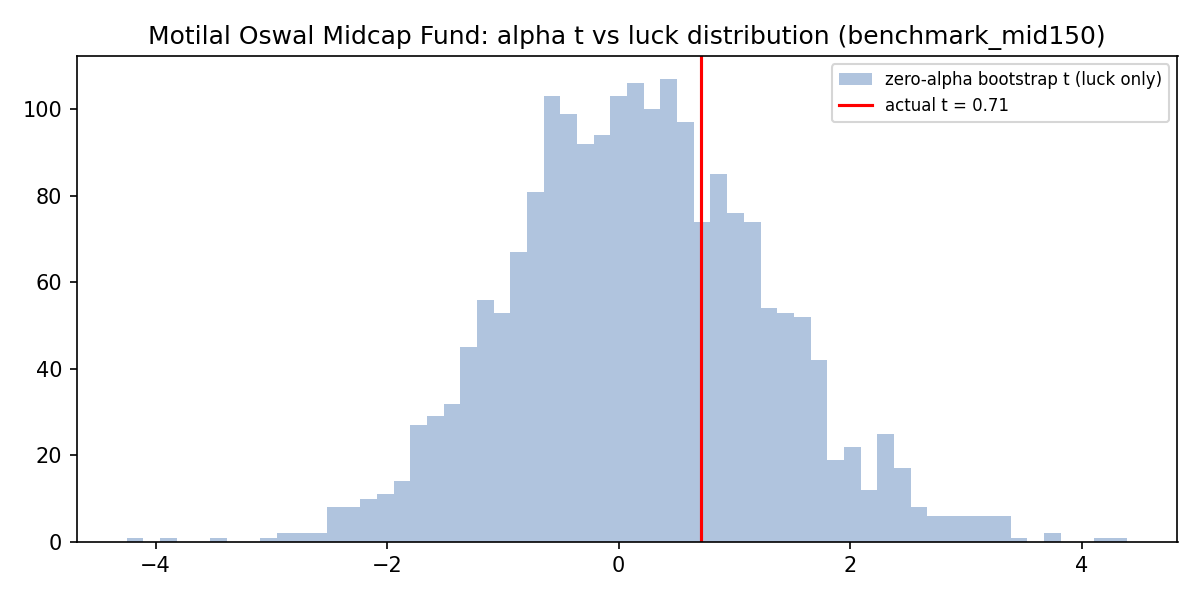

In [8]:
quiet(t5_skill_luck)
for model in ["carhart_iima", "benchmark_mid150"]:
    display(Markdown(f"**Model: {model}**"))
    display(pd.read_csv(A.RES / f"t5/{model}/target_summary.csv", index_col=0))
    display(pd.read_csv(A.RES / f"t5/{model}/cross_section_percentiles.csv").round(3))
    show(f"t5/{model}/target_t_vs_bootstrap.png", width=650)

## 7. Category league table (benchmark-relative model)

In [9]:
pd.read_csv(A.RES / "t5/benchmark_mid150/category_alpha_t_and_bootstrap_p.csv", index_col=0).round(3)

,alpha_m,t_ols,months,alpha_annualised,p_boot_fund_level,rank_t_in_category
Edelweiss Mid Cap Fund - Direct Plan - Growth Option,0.002,1.626,84.0,0.028,0.067,1
HDFC Mid Cap Fund - Growth Option - Direct Plan,0.002,1.326,84.0,0.019,0.186,2
quant Mid Cap Fund - Growth Option - Direct Plan,0.004,1.248,84.0,0.048,0.096,3
Union Midcap Fund - Direct Plan - Growth Option,0.003,1.221,78.0,0.032,0.114,4
Nippon India Growth Mid Cap Fund - Direct Plan Growth Plan - Growth Option,0.002,1.199,84.0,0.021,0.184,5
PGIM India Midcap Fund - Direct Plan - Growth Option,0.002,0.978,84.0,0.025,0.164,6
Motilal Oswal Midcap Fund-Direct Plan-Growth Option,0.002,0.709,84.0,0.026,0.306,7
BARODA BNP PARIBAS Mid Cap Fund - Direct Plan - Growth Option,0.001,0.559,54.0,0.009,0.319,8
Axis Midcap Fund - Direct Plan - Growth,0.001,0.419,84.0,0.009,0.342,9
ITI Mid Cap Fund - Direct Plan - Growth Option,0.000,0.199,66.0,0.004,0.408,10


## 8. Reading the results

* The fund beat its benchmark after fees, mainly by **falling less in down months** (down-capture < up-capture).
* **Stock selection was strong**, but **sector and cash bets cost about as much** as selection added (Brinson).
* **High active share** (~0.8): the fund is genuinely different from its index.
* The IIMA four-factor alpha looks large and significant, but the **passive mid-cap index fund also earns "alpha"**
  in that model, and almost every mid-cap fund looks skilled. Against the mid-cap benchmark, the fund's alpha is
  **not distinguishable from luck**.

See `docs/findings.md` for the full write-up and `README.md` for data sources and caveats.